In [65]:
from IPython.display import Image, display

Linear Regression
Theory: Regress means to drift towards
Developed by Sir Francis Galton (Experiment on height of a person).
Regression approach is just to minimize the distance from the fitted line (regression line) using a least square method.

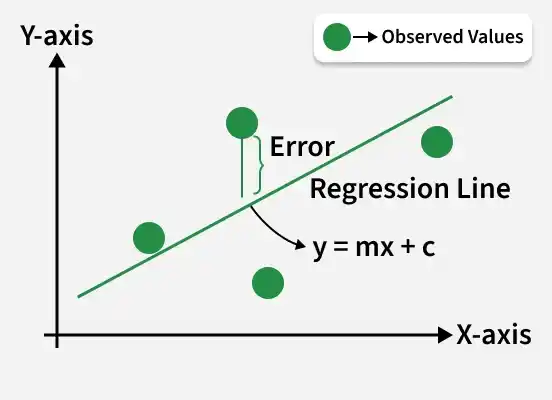


In [66]:
from pyspark.sql import SparkSession
spark=SparkSession.builder.appName("lrex").getOrCreate()

In [67]:
from pyspark.ml.regression import LinearRegression


In [ ]:
# Experiments: (A,B,C,D,E of the ML pipeline)
# Aggregate,Bucket,Create,Deploy,Evaluate are the steps of the ML pipeline.
#A : Aggregate all the Data
all_Data=spark.read.format("libsvm").load("./SilverData/Bengaluru_House_pricing_mock_data/bengaluru_housing.libsvm")
# display(all_Data) --in databricks it will work
# all_Data.show(10,truncate=False) -- here it will not truncate the data but will not display the data in a tabular format
all_Data.limit(10).toPandas() #--works in jupyter notebook to display the data in a tabular format
#observe: the features column is a vector column and the label column is a double column. 
# The features column is a vector of 4 features 
# The label column is the class of the bengaluru housing (0,1,2)

#B :Bucket the data into training and testing data
train_data,test_data=all_Data.randomSplit([0.7,0.3])
data=[('Train Data',train_data.count()),('Test Data',test_data.count()),('Train Data %',train_data.count()/all_Data.count()*100),('Test Data %',test_data.count()/all_Data.count()*100) ]

#Print the data in a tabular format
data = [(label, float(value)) for label, value in data]
print_df = spark.createDataFrame(data, ["Data Type", "Count"])
print_df.show()
# print('Train Data','Test Data','\n',train_data.count(),test_data.count(),'\n',train_data.count()/all_Data.count()*100,'%',test_data.count()/all_Data.count()*100,'%')

#C :Create a linear regression model using the training data
lr = LinearRegression().fit(train_data)

# Display training metrics
print("RMSE:", lr.summary.rootMeanSquaredError)
print("R²:", lr.summary.r2)

#D : Deploy the model on the test data and display the results
deployed_model = lr.transform(test_data)
deployed_model.show(truncate=False)

#E : Evaluate the model on the test data and returns the evaluation metrics
test_results = lr.evaluate(test_data)
print(test_results)

print("Test RMSE :", test_results.rootMeanSquaredError)
print("Test MSE  :", test_results.meanSquaredError)
print("Test MAE  :", test_results.meanAbsoluteError)
print("Test R2   :", test_results.r2)
#Theoretically,
# difference between evaluate and transform:
# - evaluate() method is used to evaluate the performance of the model on a given dataset. It returns a RegressionEvaluator object containing the evaluation metrics.
# - transform() method is used to apply the trained model to a dataset and generate predictions. It returns a DataFrame with the predicted values added as a new column.


+------------+------------------+
|   Data Type|             Count|
+------------+------------------+
|  Train Data|           38672.0|
|   Test Data|           16328.0|
|Train Data %| 70.31272727272727|
| Test Data %|29.687272727272727|
+------------+------------------+

RMSE: 0.39947070308983545
R²: 0.3955468998013738
+-----+------------------------------------------------------------------------------------------------+------------------+
|label|features                                                                                        |prediction        |
+-----+------------------------------------------------------------------------------------------------+------------------+
|1.0  |(13,[0,1,2,3,4,5,6,7,8,9,10,11,12],[4.0,1.0,872.0,1.0,8.72,3.0,2.0,7.28,3.0,2.0,2.0,1.0,6.0])   |2.905291766192107 |
|1.0  |(13,[0,1,2,3,4,5,6,7,8,9,10,11,12],[4.0,1.0,925.0,1.0,7.87,1.0,1.0,8.05,4.0,2.0,4.0,10.0,3.0])  |2.9790636313062597|
|1.0  |(13,[0,1,2,3,4,5,6,7,8,9,10,11,12],[4.0,1.0,1714.0,

In [ ]:
#Final Regression Pipeline:
path="./SilverData/Bengaluru_House_pricing_mock_data/bengaluru_housing.libsvm"
seed=42
# A. Aggregate
all_Data = spark.read.format("libsvm").load(path)

# B. Bucket
train_data, test_data = all_Data.randomSplit([0.7, 0.3], seed)

# C. Create 
lr = LinearRegression()
model = lr.fit(train_data)

# D. Deploy
predictions = model.transform(test_data)
predictions.show()

# E. Evaluate
evaluation = model.evaluate(test_data)

print("RMSE:", evaluation.rootMeanSquaredError)
print("MAE :", evaluation.meanAbsoluteError)
print("R2  :", evaluation.r2)

+-----+--------------------+------------------+
|label|            features|        prediction|
+-----+--------------------+------------------+
|  1.0|(13,[0,1,2,3,4,5,...| 2.005724632670584|
|  1.0|(13,[0,1,2,3,4,5,...|2.6079826635650862|
|  1.0|(13,[0,1,2,3,4,5,...|2.9337578079452937|
|  1.0|(13,[0,1,2,3,4,5,...|  2.89579986954094|
|  1.0|(13,[0,1,2,3,4,5,...|2.4368905061067387|
|  1.0|(13,[0,1,2,4,5,6,...|2.4315724288552945|
|  1.0|(13,[0,1,2,4,5,6,...|2.1810067458742255|
|  2.0|(13,[0,1,2,3,4,5,...| 3.257774761526765|
|  2.0|(13,[0,1,2,3,4,5,...|2.6633658105480604|
|  2.0|(13,[0,1,2,3,4,5,...| 3.290223405640417|
|  2.0|(13,[0,1,2,3,4,5,...| 2.745473091836848|
|  2.0|(13,[0,1,2,3,4,5,...|2.6902598263419426|
|  2.0|(13,[0,1,2,3,4,5,...| 3.252683003735072|
|  2.0|(13,[0,1,2,3,4,5,...| 3.085921191359564|
|  2.0|(13,[0,1,2,3,4,5,...|3.0365912723578905|
|  2.0|(13,[0,1,2,3,4,5,...|2.6192729548487708|
|  2.0|(13,[0,1,2,3,4,5,...|2.7914611459405947|
|  2.0|(13,[0,1,2,3,4,5,...|3.1099021243

: 